# Mushroom Identification Project

In [1]:
!ls

Mushroom_Project.ipynb	sample_submission.csv	   test.csv	 train.csv
README.md		sample_submission.csv.zip  test.csv.zip  train.csv.zip


In [46]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

# ----- CHANGE THESE FOR YOUR PROJECT -----
DATA_PATH = '/Fall_2026/DATA-3402/Kaggle_Project.train.csv'
TARGET = "class"    

# Keep pair plots manageable.
MAX_PAIRPLOT_FEATURES = 5
MAX_PAIRPLOT_ROWS = 1500

In [47]:
df = pd.read_csv('train.csv')
df.head()

,id,class,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-height,stem-width,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
0,0,e,8.80,f,s,u,f,a,c,w,4.51,15.39,NaN,NaN,w,NaN,NaN,f,f,NaN,d,a
1,1,p,4.51,x,h,o,f,a,c,n,4.79,6.48,NaN,y,o,NaN,NaN,t,z,NaN,d,w
2,2,e,6.94,f,s,b,f,x,c,w,6.85,9.93,NaN,s,n,NaN,NaN,f,f,NaN,l,w
3,3,e,3.88,f,y,g,f,s,NaN,g,4.16,6.53,NaN,NaN,w,NaN,NaN,f,f,NaN,d,u
4,4,e,5.85,x,l,w,f,d,NaN,w,3.37,8.36,NaN,NaN,w,NaN,NaN,f,f,NaN,g,a


In [48]:
df.shape

(3116945, 22)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3116945 entries, 0 to 3116944
Data columns (total 22 columns):
 #   Column                Dtype  
---  ------                -----  
 0   id                    int64  
 1   class                 object 
 2   cap-diameter          float64
 3   cap-shape             object 
 4   cap-surface           object 
 5   cap-color             object 
 6   does-bruise-or-bleed  object 
 7   gill-attachment       object 
 8   gill-spacing          object 
 9   gill-color            object 
 10  stem-height           float64
 11  stem-width            float64
 12  stem-root             object 
 13  stem-surface          object 
 14  stem-color            object 
 15  veil-type             object 
 16  veil-color            object 
 17  has-ring              object 
 18  ring-type             object 
 19  spore-print-color     object 
 20  habitat               object 
 21  season                object 
dtypes: float64(3), int64(1), object(18)
memory

In [11]:
df.isna().sum()

id                            0
class                         0
cap-diameter                  4
cap-shape                    40
cap-surface              671023
cap-color                    12
does-bruise-or-bleed          8
gill-attachment          523936
gill-spacing            1258435
gill-color                   57
stem-height                   0
stem-width                    0
stem-root               2757023
stem-surface            1980861
stem-color                   38
veil-type               2957493
veil-color              2740947
has-ring                     24
ring-type                128880
spore-print-color       2849682
habitat                      45
season                        0
dtype: int64

In [49]:
# replace target with 1 and 0 as target vs. background
df['class'] = df['class'].replace({'e':1, 'p':0})

/tmp/ipykernel_1547/1738516523.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['class'] = df['class'].replace({'e':1, 'p':0})


In [50]:
df.head()

,id,class,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-height,stem-width,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
0,0,1,8.80,f,s,u,f,a,c,w,4.51,15.39,NaN,NaN,w,NaN,NaN,f,f,NaN,d,a
1,1,0,4.51,x,h,o,f,a,c,n,4.79,6.48,NaN,y,o,NaN,NaN,t,z,NaN,d,w
2,2,1,6.94,f,s,b,f,x,c,w,6.85,9.93,NaN,s,n,NaN,NaN,f,f,NaN,l,w
3,3,1,3.88,f,y,g,f,s,NaN,g,4.16,6.53,NaN,NaN,w,NaN,NaN,f,f,NaN,d,u
4,4,1,5.85,x,l,w,f,d,NaN,w,3.37,8.36,NaN,NaN,w,NaN,NaN,f,f,NaN,g,a


In [51]:
df = df.drop(columns = 'id')
df.head()

,class,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-height,stem-width,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
0,1,8.80,f,s,u,f,a,c,w,4.51,15.39,NaN,NaN,w,NaN,NaN,f,f,NaN,d,a
1,0,4.51,x,h,o,f,a,c,n,4.79,6.48,NaN,y,o,NaN,NaN,t,z,NaN,d,w
2,1,6.94,f,s,b,f,x,c,w,6.85,9.93,NaN,s,n,NaN,NaN,f,f,NaN,l,w
3,1,3.88,f,y,g,f,s,NaN,g,4.16,6.53,NaN,NaN,w,NaN,NaN,f,f,NaN,d,u
4,1,5.85,x,l,w,f,d,NaN,w,3.37,8.36,NaN,NaN,w,NaN,NaN,f,f,NaN,g,a


In [52]:
df.columns

Index(['class', 'cap-diameter', 'cap-shape', 'cap-surface', 'cap-color',
       'does-bruise-or-bleed', 'gill-attachment', 'gill-spacing', 'gill-color',
       'stem-height', 'stem-width', 'stem-root', 'stem-surface', 'stem-color',
       'veil-type', 'veil-color', 'has-ring', 'ring-type', 'spore-print-color',
       'habitat', 'season'],
      dtype='object')

In [53]:
df_clean = df.copy()

In [54]:
valid_values = {'cap-shape':['b','c','x','f','k','s'], 
                'cap-surface':['f','g','y','s'], 
                'cap-color':['n','b','c','g','r','p','u','e','w','y'],
                'does-bruise-or-bleed':['t','f'],
                'gill-attachment':['a','d','f','n'],
                'gill-spacing':['c','w','d'],
                'gill-color':['k','n','b','h','g','r','o','p','u','e','w','y'],
                'stem-root':['b','c','u','e','z','r','?'],
                'stem-surface':['f','y','k','s'],
                'stem-color':['n','b','c','g','o','p','e','w','y'],
                'veil-type':['p','u'],
                'veil-color':['n','o','w','y'],
                'has-ring':['f','t'],
                'ring-type':['c','e','f','l','n','p','s','z'],
                'spore-print-color':['k','n','b','h','r','o','u','w','y'],
                'habitat':['g','l','m','p','u','w','d'],
                'season':['a','s','u','w']}

for column, values in valid_values.items():
    df_clean = df_clean[df_clean[column].isin(values)]

In [56]:
df_clean.shape

(0, 21)

In [57]:
df_clean = df.copy()

for column, values in valid_values.items():
    before = len(df_clean)
    df_clean = df_clean[df_clean[column].isin(values)]
    print(f"{column}: {before} → {len(df_clean)}")

cap-shape: 3116945 → 2900589
cap-surface: 2900589 → 905283
cap-color: 905283 → 824124
does-bruise-or-bleed: 824124 → 824099
gill-attachment: 824099 → 333857
gill-spacing: 333857 → 188778
gill-color: 188778 → 188725
stem-root: 188725 → 144
stem-surface: 144 → 25
stem-color: 25 → 25
veil-type: 25 → 0
veil-color: 0 → 0
has-ring: 0 → 0
ring-type: 0 → 0
spore-print-color: 0 → 0
habitat: 0 → 0
season: 0 → 0


In [58]:
df_clean = df.copy()

for column, values in valid_values.items():
    before = len(df_clean)

    df_clean = df_clean[
        df_clean[column].isin(values) | df_clean[column].isna()
    ]

    print(f"{column}: {before} → {len(df_clean)}")

cap-shape: 3116945 → 2900629
cap-surface: 2900629 → 1487129
cap-color: 1487129 → 1361904
does-bruise-or-bleed: 1361904 → 1361864
gill-attachment: 1361864 → 815445
gill-spacing: 815445 → 775294
gill-color: 775294 → 774888
stem-root: 774888 → 736129
stem-surface: 736129 → 661370
stem-color: 661370 → 646377
veil-type: 646377 → 646366
veil-color: 646366 → 646349
has-ring: 646349 → 646331
ring-type: 646331 → 606186
spore-print-color: 606186 → 606136
habitat: 606136 → 576666
season: 576666 → 576666


In [60]:
print(type(df_clean))
print(df.shape)

<class 'pandas.core.frame.DataFrame'>
(3116945, 21)


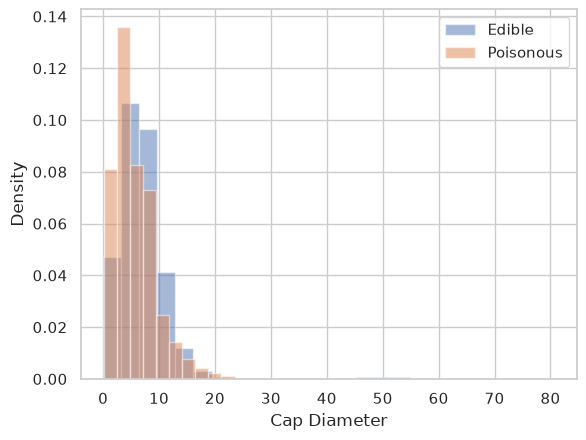

In [61]:
plt.hist(df.loc[df["class"] == 1, "cap-diameter"],
         alpha=0.5, density=True, bins=25, label="Edible")

plt.hist(df.loc[df["class"] == 0, "cap-diameter"],
         alpha=0.5, density=True, bins=25, label="Poisonous")

plt.xlabel("Cap Diameter")
plt.ylabel("Density")
plt.legend()
plt.show()

In [75]:
def categorical_features(df, ax=None):
    for column in df.select_dtypes(include=['object', 'string']).columns:
        counts = df.groupby([column, 'class']).size().unstack(fill_value=0)

        counts.plot(kind='bar', ax=ax)

        plt.xlabel(column)
        plt.ylabel('Count')
        plt.legend(['Poisonous', 'Edible'])
        
def categorical_subplots(df):
    columns = df.select_dtypes(include=['object', 'string']).columns
    fig, ax = plt.subplots(6, 3, figsize=(18, 24))

    for i, column in enumerate(columns):
        categorical_features(df[[column, 'class']], ax=ax.flatten()[i])

    plt.tight_layout()
    plt.show()

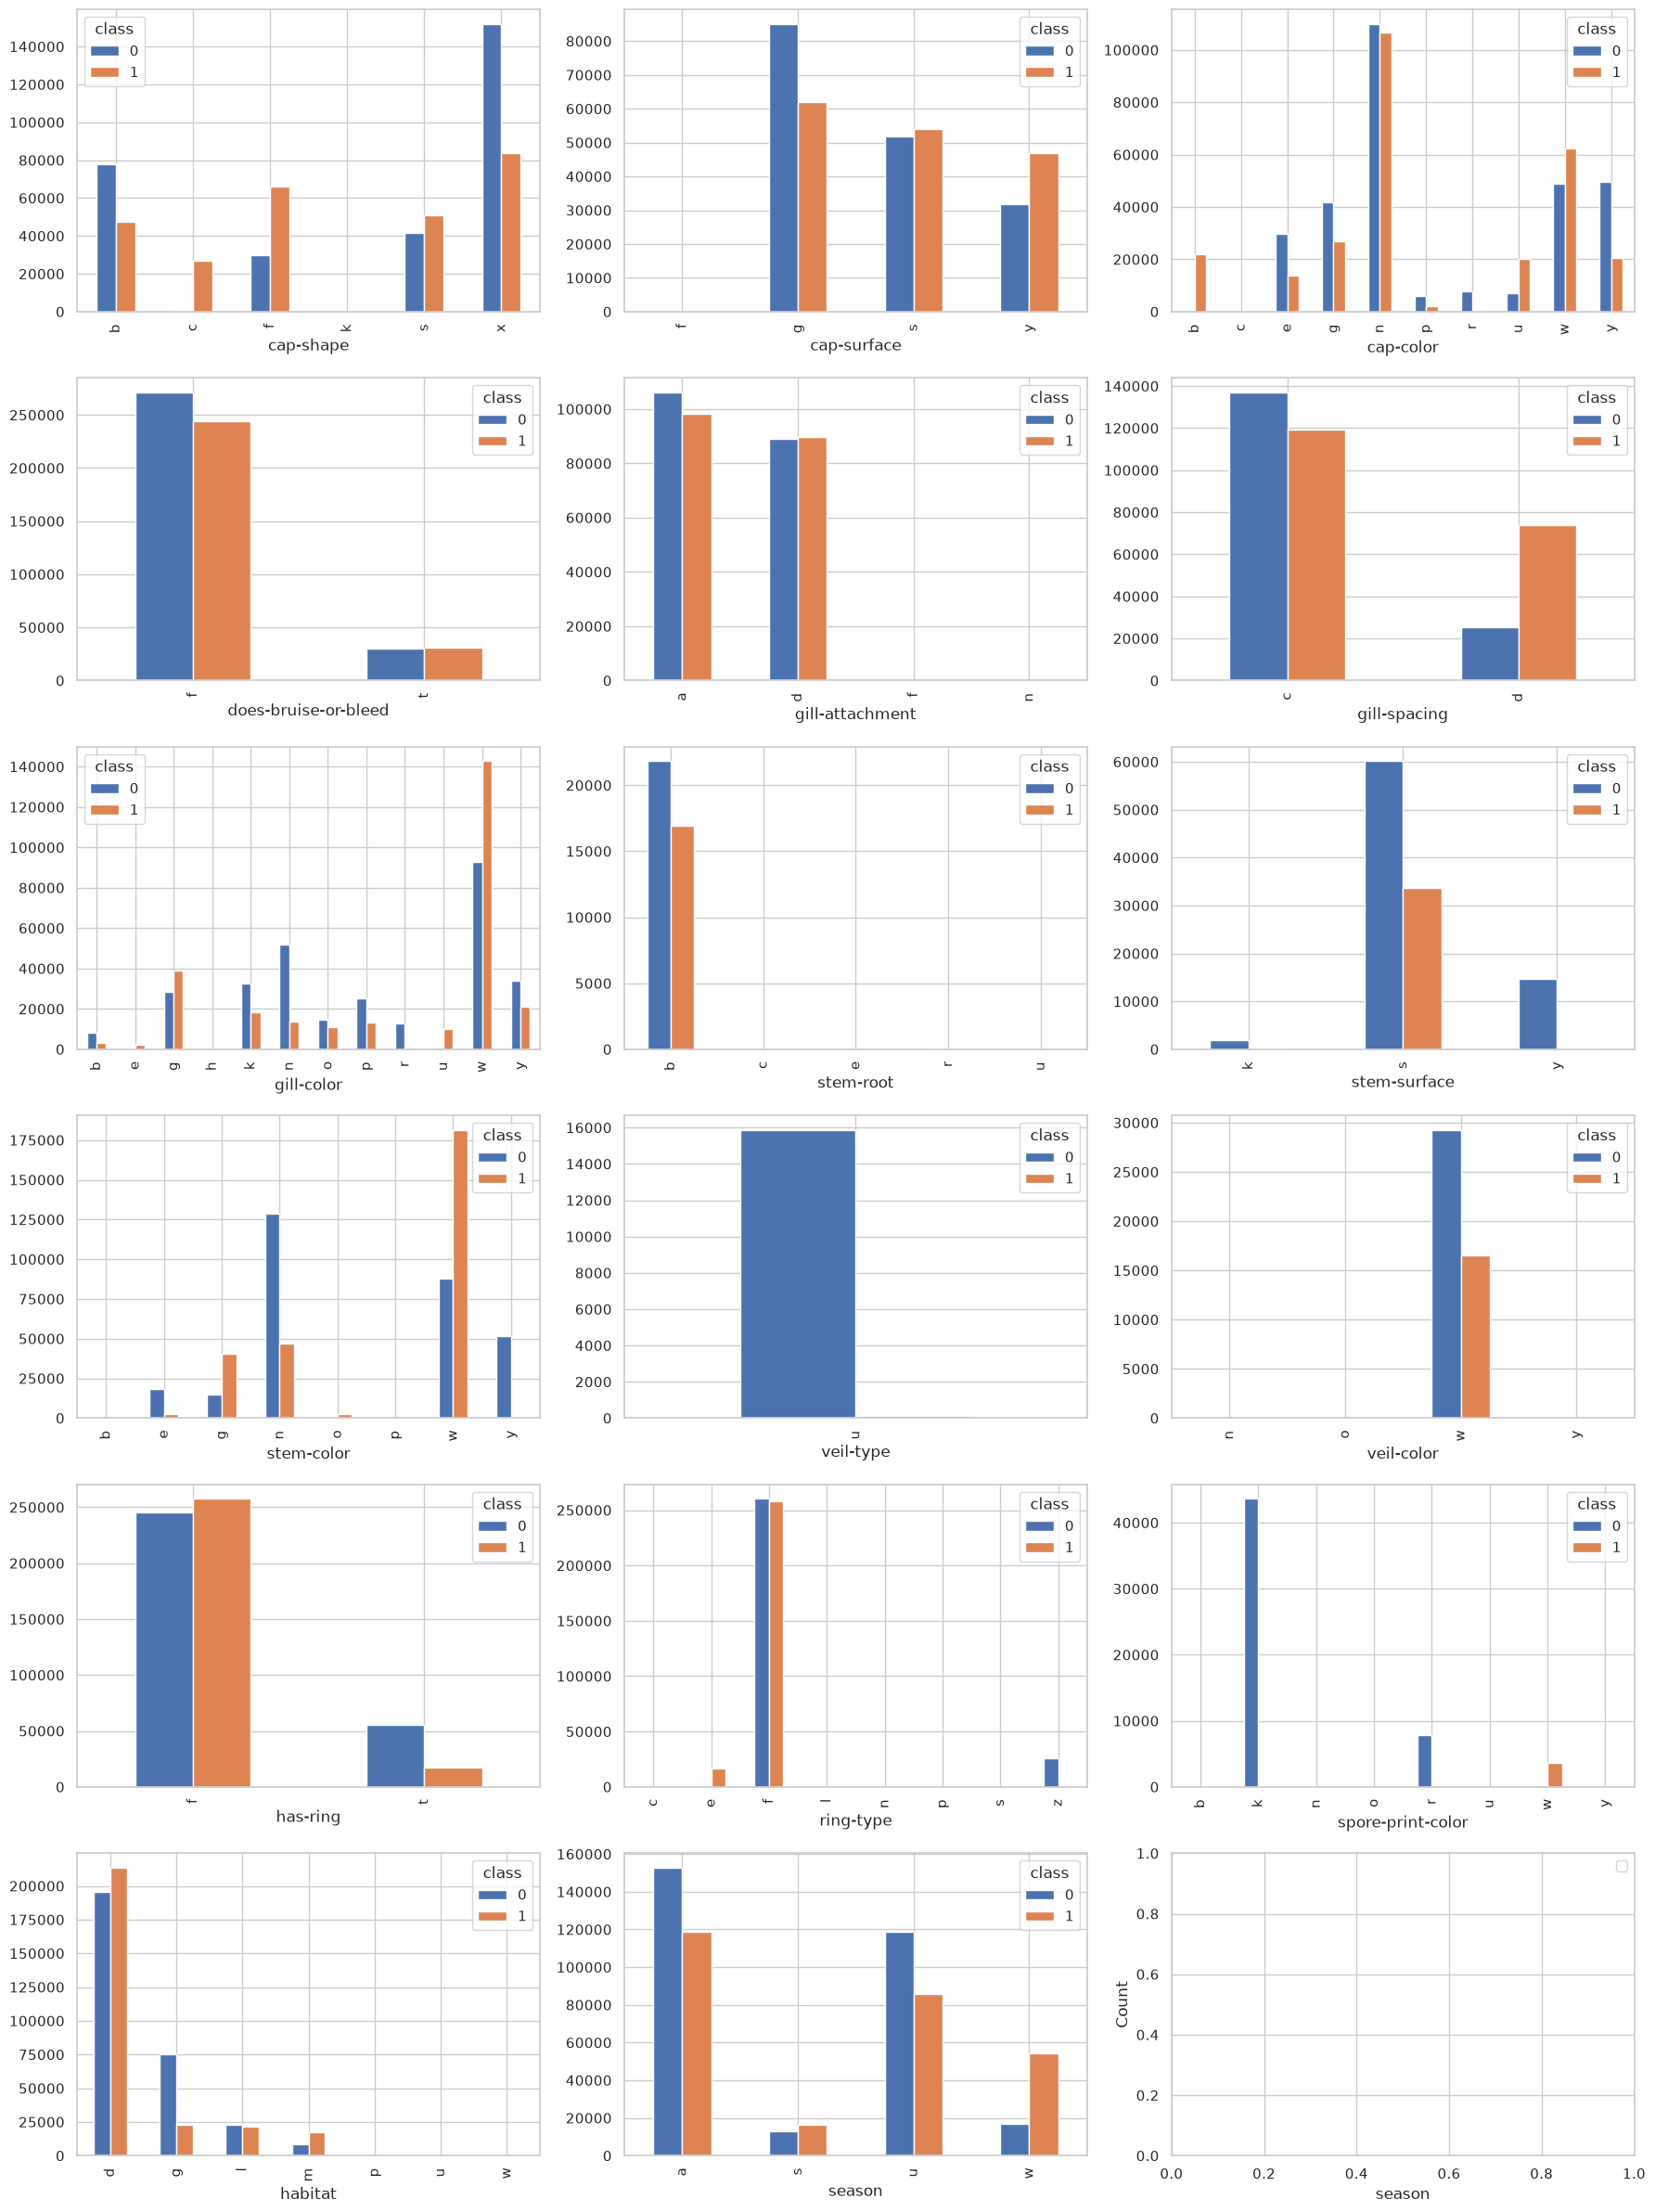

In [76]:
categorical_subplots(df_clean)

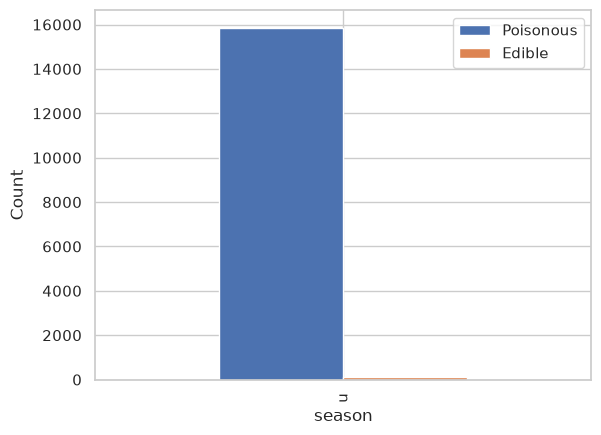

In [80]:
counts = df_clean.groupby(['veil-type', 'class']).size().unstack(fill_value=0)

counts.plot(kind='bar')

plt.xlabel(column)
plt.ylabel('Count')
plt.legend(['Poisonous', 'Edible'])

In [81]:
valid_values['veil-type']

['p', 'u']